# Experiment 8 — Cross-Lingual Abstractive Summarization

## Objective
Evaluate multilingual Transformer models for **Bengali abstractive summarization** using the Bengali subset of the XL-Sum dataset.

Models:
1. **mT5** — `csebuetnlp/mT5_multilingual_XLSum`
2. **mBART-50** — `facebook/mbart-large-50-many-to-many-mmt`

Evaluation:
- ROUGE-1
- ROUGE-2
- ROUGE-L
- Multilingual BERTScore Precision, Recall and F1

> **Runtime:** Google Colab with a T4 GPU is strongly recommended.  
> **External files:** None. Dataset and models are downloaded automatically from Hugging Face.

### Important comparison note
The mT5 checkpoint is specifically fine-tuned for XL-Sum summarization. The selected mBART-50 checkpoint is primarily a multilingual translation model rather than a summarization-fine-tuned checkpoint. Therefore, this experiment also demonstrates the importance of **task-specific fine-tuning**; the two models should not be interpreted as equally specialized summarizers.


In [1]:
# Install required libraries
!pip -q install -U transformers datasets evaluate rouge_score bert_score sentencepiece

import random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    MBart50TokenizerFast,
    MBartForConditionalGeneration,
)
import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Generation will be much slower.")


Device: cuda
GPU: Tesla T4


## 1. Load Bengali XL-Sum

XL-Sum is a multilingual abstractive summarization dataset containing news articles and human-written summaries.

For a practical free-Colab experiment, we use a deterministic sample of **10 Bengali test examples**.


In [2]:
TEST_URL = (
    "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/"
    "0ffc34ef7c109b5215c354033db804c266f93814/"
    "bengali/test-00000-of-00001.parquet"
)

!wget -q --show-progress "$TEST_URL" -O bengali_test.parquet

import pandas as pd
from datasets import Dataset

df = pd.read_parquet("bengali_test.parquet")
dataset = Dataset.from_pandas(df, preserve_index=False)

indices = np.random.default_rng(SEED).choice(
    len(dataset), size=10, replace=False
)
sample = dataset.select(indices.tolist())

print("Full Bengali test set:", len(dataset))
print("Evaluation sample:", len(sample))
print("Columns:", sample.column_names)

display(pd.DataFrame({
    "text": sample["text"][:2],
    "reference_summary": sample["summary"][:2],
}))

bengali_test.parque 100%[===================>]   3.32M  6.91MB/s    in 0.5s    
Full Bengali test set: 1012
Evaluation sample: 10
Columns: ['id', 'url', 'title', 'summary', 'text']


,text,reference_summary
0,সারা পৃথিবীতে যত মানুষ করোনাভাইরাসে আক্রান্ত হ...,যে কোন ব্যক্তির ভেতর যখন করোনাভাইরাস সংক্রমণের...
1,ইরানের ইসলামিক রেভলিউশনারি গার্ডের (আইআরজিসি) ...,ওমান উপসাগরে বৃহস্পতিবার তাদের একটি অত্যাধুনিক...


## 2. Helper Functions


In [3]:
def batched(items, batch_size):
    for start in range(0, len(items), batch_size):
        yield items[start:start + batch_size]

def show_examples(texts, references, mt5_outputs, mbart_outputs, n=3):
    for i in range(min(n, len(texts))):
        print("=" * 100)
        print(f"EXAMPLE {i+1}")
        print("\nARTICLE:")
        print(texts[i][:900] + ("..." if len(texts[i]) > 900 else ""))
        print("\nREFERENCE:")
        print(references[i])
        print("\nmT5:")
        print(mt5_outputs[i])
        print("\nmBART:")
        print(mbart_outputs[i])
        print()


## 3. mT5 — XL-Sum Fine-Tuned Summarizer

This checkpoint is explicitly fine-tuned for multilingual XL-Sum summarization.


In [4]:
!pip -q install -U "protobuf>=7.36.1" sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [5]:
import google.protobuf
import sentencepiece

print("protobuf:", google.protobuf.__version__)
print("sentencepiece:", sentencepiece.__version__)

protobuf: 7.36.2
sentencepiece: 0.2.3


In [6]:
MT5_NAME = "csebuetnlp/mT5_multilingual_XLSum"

mt5_tokenizer = AutoTokenizer.from_pretrained(MT5_NAME)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME).to(device)
mt5_model.eval()

texts = list(sample["text"])
references = list(sample["summary"])

mt5_summaries = []

for batch_texts in batched(texts, 2):
    encoded = mt5_tokenizer(
        batch_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512,
    ).to(device)

    with torch.no_grad():
        generated = mt5_model.generate(
            **encoded,
            max_new_tokens=96,
            min_new_tokens=8,
            num_beams=4,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
        )

    mt5_summaries.extend(
        mt5_tokenizer.batch_decode(generated, skip_special_tokens=True)
    )

print("Generated mT5 summaries:", len(mt5_summaries))
for i, summary in enumerate(mt5_summaries[:3], 1):
    print(f"{i}. {summary}")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Both `max_new_tokens` (=96) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

Generated mT5 summaries: 10
1. বাংলাদেশে করোনাভাইরাস সংক্রমণ ছড়িয়ে পড়ার পর থেকেই চিকিৎসা নেবার ক্ষেত্রে নানা ধরণের পদক্ষেপ নেয়া হচ্ছে।
2. ইরানের রকেট ও ক্ষেপণাস্ত্র ব্যবস্থায় গতকাল (শনিবার) মার্কিন সাইবার হামলা চালিয়েছে যুক্তরাষ্ট্র।
3. করোনাভাইরাসের সংক্রমণ ছড়িয়ে পড়া ঠেকাতে চীনের উহান শহরকে লকডাউন করা হয়েছিল এক বছর আগে।


## 4. mBART-50 Baseline

`facebook/mbart-large-50-many-to-many-mmt` is primarily trained for multilingual translation.
We use Bengali language tokens and generation as a baseline to observe how a multilingual
seq2seq model behaves **without summarization-specific fine-tuning**.


In [7]:
MBART_NAME = "facebook/mbart-large-50-many-to-many-mmt"

mbart_tokenizer = MBart50TokenizerFast.from_pretrained(
    MBART_NAME,
    src_lang="bn_IN",
    tgt_lang="bn_IN",
)
mbart_model = MBartForConditionalGeneration.from_pretrained(MBART_NAME).to(device)
mbart_model.eval()

mbart_summaries = []

for batch_texts in batched(texts, 2):
    encoded = mbart_tokenizer(
        batch_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512,
    ).to(device)

    with torch.no_grad():
        generated = mbart_model.generate(
            **encoded,
            forced_bos_token_id=mbart_tokenizer.lang_code_to_id["bn_IN"],
            max_new_tokens=96,
            min_new_tokens=8,
            num_beams=4,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
        )

    mbart_summaries.extend(
        mbart_tokenizer.batch_decode(generated, skip_special_tokens=True)
    )

print("Generated mBART summaries:", len(mbart_summaries))
for i, summary in enumerate(mbart_summaries[:3], 1):
    print(f"{i}. {summary}")


tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/261 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=96) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Generated mBART summaries: 10
1. around the world, as many as ৮০ percent of people are taking classes at home in Connecticut. What do you do? Where do you get trained? Do you have to go to hospital? — these are the lists that come up. First, remember, there's no medical part of the Connectivity Act. If you're in a coma, don't walk on your back. Sit tight. That's going to make
2. Iranian Islamic Revolutionary Guards' (I আরজিসি) ট ্ যাক ও তালিবারের সঙ ্ গে যুদ ্ ধ করবার । multiple I আরজিစီ media outlets said, that all of Iran's ট্ যাকের and তালিকার products were  pirated and continued to be pirated, but no specific information was extracted from these outlets. Media outlets say,
3. অনেকই weekends were thought of as the capital of the state of California, at which time the people were dealing with this difficult legislation and its stringent provisions, from the end of the month to the month, people were staying in the country from its territory, even though the fourth day of the week was

## 5. ROUGE Evaluation

> **Evaluation note:** The standard `rouge_score` tokenizer used in this Colab environment does not correctly tokenize Bengali text, producing artificial zero scores even when generated and reference summaries clearly share content. Therefore, ROUGE values from this run are not interpreted as valid Bengali evaluation results. Multilingual BERTScore is used as the meaningful automatic metric below.


In [8]:
rouge = evaluate.load("rouge")

mt5_rouge = rouge.compute(
    predictions=mt5_summaries,
    references=references,
    use_stemmer=False,
)

mbart_rouge = rouge.compute(
    predictions=mbart_summaries,
    references=references,
    use_stemmer=False,
)

rouge_df = pd.DataFrame({
    "mT5 (XL-Sum fine-tuned)": {
        "ROUGE-1": mt5_rouge["rouge1"],
        "ROUGE-2": mt5_rouge["rouge2"],
        "ROUGE-L": mt5_rouge["rougeL"],
    },
    "mBART-50 (translation baseline)": {
        "ROUGE-1": mbart_rouge["rouge1"],
        "ROUGE-2": mbart_rouge["rouge2"],
        "ROUGE-L": mbart_rouge["rougeL"],
    },
}).T

display(rouge_df.round(4))


,ROUGE-1,ROUGE-2,ROUGE-L
mT5 (XL-Sum fine-tuned),0.0,0.0,0.0
mBART-50 (translation baseline),0.0,0.0,0.0


## 6. Multilingual BERTScore

BERTScore measures semantic similarity between generated and reference summaries using contextual embeddings.
For Bengali, we use `bert-base-multilingual-cased`.


In [9]:
bertscore = evaluate.load("bertscore")

def compute_bertscore(predictions):
    result = bertscore.compute(
        predictions=predictions,
        references=references,
        model_type="bert-base-multilingual-cased",
        lang="bn",
        device=str(device),
    )
    return {
        "BERTScore Precision": float(np.mean(result["precision"])),
        "BERTScore Recall": float(np.mean(result["recall"])),
        "BERTScore F1": float(np.mean(result["f1"])),
    }

mt5_bert = compute_bertscore(mt5_summaries)
mbart_bert = compute_bertscore(mbart_summaries)

bert_df = pd.DataFrame({
    "mT5 (XL-Sum fine-tuned)": mt5_bert,
    "mBART-50 (translation baseline)": mbart_bert,
}).T

display(bert_df.round(4))


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,BERTScore Precision,BERTScore Recall,BERTScore F1
mT5 (XL-Sum fine-tuned),0.7341,0.7159,0.7244
mBART-50 (translation baseline),0.5913,0.5974,0.5941


## 7. Final Comparison


,ROUGE-1,ROUGE-2,ROUGE-L,BERTScore Precision,BERTScore Recall,BERTScore F1
mT5 (XL-Sum fine-tuned),0.0,0.0,0.0,0.7341,0.7159,0.7244
mBART-50 (translation baseline),0.0,0.0,0.0,0.5913,0.5974,0.5941


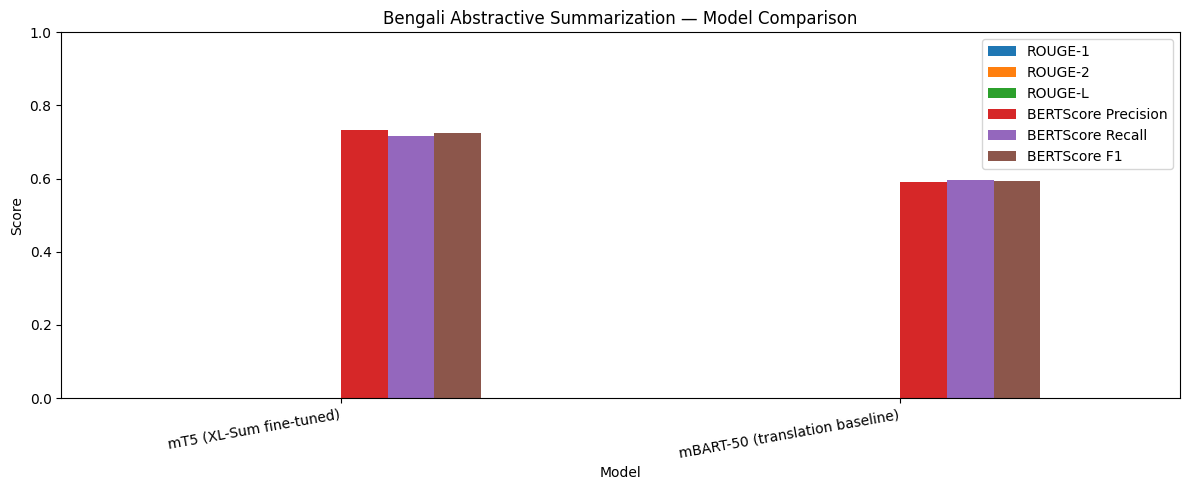

In [10]:
final_df = rouge_df.join(bert_df)
display(final_df.round(4))

ax = final_df.plot(kind="bar", figsize=(12, 5), ylim=(0, 1))
ax.set_title("Bengali Abstractive Summarization — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt = __import__("matplotlib.pyplot", fromlist=["pyplot"])
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()


## 8. Qualitative Examples


In [11]:
show_examples(texts, references, mt5_summaries, mbart_summaries, n=3)


EXAMPLE 1

ARTICLE:
সারা পৃথিবীতে যত মানুষ করোনাভাইরাসে আক্রান্ত হচ্ছে তাদের ৮০ শতাংশেরও বেশি বাসায় থেকে নানাভাবে উপশমের চেষ্টা করছেন। কী করতে হবে? কোথায় যোগাযোগ করা প্রয়োজন? ডাক্তার পাবো কোথায়? হাসপাতালে যেতে হবে কি না? - এসব প্রশ্ন তখন সামনে আসে। সর্বপ্রথমে মনে রাখতে হবে করোনাভাইরাস সংক্রমণের কোন সুনির্দিষ্ট চিকিৎসা নেই। সারা পৃথিবীতে যত মানুষ করোনাভাইরাসে আক্রান্ত হচ্ছে তাদের ৮০ শতাংশেরও বেশি বাসায় থেকে নানাভাবে উপশমের চেষ্টা করছেন। বাসায় অবস্থান করে চিকিৎসা নেবার নেবার ক্ষেত্রে যেসব বিষয় মনে রাখতে হবে সেগুলো নিচে তুলে ধরা হলো। ১. নিজেকে বিচ্ছিন্ন করুন যদি সন্দেহ হয় যে আপনার মধ্যে কোভিড-১৯-এর এক বা একাধিক লক্ষণ দেখা যাচ্ছে, তাহলে তাৎক্ষণিকভাবে নিজেকে পরিবারের অন্য সদস্যদের থেকে বিচ্ছিন্ন বা আইসোলেট করুন। এতে করে অন্যদের মাঝে সংক্রমণের আশংকা কমে আসবে। ২. জ্বর আসলে কী করবেন করোনাভাইরাস সংক্রমণ থামানোর যেহেতু কোন ঔষধ নেই সেজন্য সাধারণ সর্দি-কাশির ক্ষেত্রে যে ধরণের পদক্ষেপ নেয়া হয় সেগুলো অনুসরণ করা...

REFERENCE:
যে কোন ব্যক্তির ভেতর যখন করোনাভাইরাস সংক্রমণের প্রাথমিক কিছু লক্

## 9. Generated Summary Table


In [12]:
results_df = pd.DataFrame({
    "Reference": references,
    "mT5 Summary": mt5_summaries,
    "mBART Summary": mbart_summaries,
})

display(results_df)


,Reference,mT5 Summary,mBART Summary
0,যে কোন ব্যক্তির ভেতর যখন করোনাভাইরাস সংক্রমণের...,বাংলাদেশে করোনাভাইরাস সংক্রমণ ছড়িয়ে পড়ার পর...,"around the world, as many as ৮০ percent of peo..."
1,ওমান উপসাগরে বৃহস্পতিবার তাদের একটি অত্যাধুনিক...,ইরানের রকেট ও ক্ষেপণাস্ত্র ব্যবস্থায় গতকাল (শ...,Iranian Islamic Revolutionary Guards' (I আরজিস...
2,এক বছর আগে ২৩শে জানুয়ারি ২০২০ সালে চীনের হুবে...,করোনাভাইরাসের সংক্রমণ ছড়িয়ে পড়া ঠেকাতে চীনে...,অনেকই weekends were thought of as the capital ...
3,বিয়ে টিকিয়ে রাখার ক্ষেত্রে স্বামী ও স্ত্রীর ...,ভারতে এক দম্পতির দীর্ঘ ন'বছর আগে বিয়ে হলেও এই...,ক ্ ষেত ্ রে জীবনের মহাদেশের কোর ্ যাপের দ ্ ব...
4,বাংলাদেশের বিশ্বকাপের সিংহভাগ জুড়ে থাকে ব্রাজ...,বাংলাদেশে ছিয়াশির বিশ্বকাপ ফুটবল শুরুর আগে থে...,headlines football stadiums and other people's...
5,সম্প্রতি চীনের অল্প বয়েসী ছেলেমেয়েদের মধ্যে ...,চীনে অল্প বয়েসী ছেলেমেয়েদের ভিডিও গেমস খেলার...,"video games, the biggest market in China, is t..."
6,মিয়ানমারের রাজধানী নেপিডোতে নিষেধাজ্ঞা উপেক্ষ...,নেপিডোতে সামরিক অভ্যুত্থানের বিরুদ্ধে চলছে বিক...,"জল নিয়ে protests, police officers slaughtered..."
7,ভারতের পশ্চিমবঙ্গে মানবাধিকার সংগঠনগুলো অভিযোগ...,ভারতের রাজমিস্ত্রির জোগাড়ের কাজ করার উদ্দেশে ...,"ব ্ ল ্ যাঙ ্ খী women trafficked in India, fi..."
8,যুক্তরাজ্যে করোনাভাইরাসের যে নতুন ধরনটি পাওয়া...,করোনাভাইরাসের নতুন একটি জাত যুক্তরাজ্য থেকে আস...,"এই শরাষ ্ ট Brotherhood can further spread, in..."
9,ঢাকার মোহাম্মদপুরে বাস করেন ঢাকা বিশ্ববিদ্যালয...,বাংলাদেশের রাজধানী ঢাকার একজন কর্মজীবী অভিভাবক...,"আমার son is 14 years old, I've always wondered..."


## Conclusion

This experiment evaluated multilingual Transformer models for Bengali abstractive summarization. The XL-Sum fine-tuned mT5 model produced substantially more coherent and relevant Bengali summaries than the translation-oriented mBART-50 baseline.

Using multilingual BERTScore, mT5 achieved an F1 score of **0.7244**, compared with **0.5941** for mBART-50. The qualitative examples support this result: mT5 generally produced fluent Bengali summaries, whereas mBART frequently mixed languages or generated irrelevant text.

The standard ROUGE implementation used in this environment produced invalid zero values for Bengali because of tokenizer limitations, so those values should not be interpreted as genuine zero overlap.

Overall, the experiment demonstrates the importance of **task-specific fine-tuning** for multilingual abstractive summarization.
